In [ ]:
# Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

import seaborn as sns
sns.set(style="whitegrid")

# make pandas outputs more readable
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 20)

---
## Data import

In [3]:
body_file = "soc-redditHyperlinks-body.tsv"
title_file = "soc-redditHyperlinks-title.tsv"

def read_hyperlink_tsv(path, nrows=None):
    """
    Load subreddit hyperlink TSV file.
    Columns:
    SOURCE_SUBREDDIT, TARGET_SUBREDDIT, POST_ID, TIMESTAMP, LINK_SENTIMENT, PROPERTIES
    """
    df = pd.read_csv(
        path,
        sep="\t",
        header=0,
        nrows=nrows,
        dtype={
            "SOURCE_SUBREDDIT": str,
            "TARGET_SUBREDDIT": str,
            "POST_ID": str,
            "TIMESTAMP": str,
            "LINK_SENTIMENT": str,
            "PROPERTIES": str,
        },
    )
    return df

print("Loading body hyperlinks …")
df_body = read_hyperlink_tsv("./data/" + body_file)

print("Loading title hyperlinks …")
df_title = read_hyperlink_tsv("./data/" + title_file)

df_body["LINK_SENTIMENT"] = pd.to_numeric(df_body["LINK_SENTIMENT"], errors="coerce")

display(df_body)
display(df_title)

Loading body hyperlinks …
Loading title hyperlinks …


,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,PROPERTIES
0,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,"345.0,298.0,0.75652173913,0.0173913043478,0.08..."
1,theredlion,soccer,1u4qkd,2013-12-31 18:18:37,-1,"101.0,98.0,0.742574257426,0.019801980198,0.049..."
2,inlandempire,bikela,1u4qlzs,2014-01-01 14:54:35,1,"85.0,85.0,0.752941176471,0.0235294117647,0.082..."
3,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,"1124.0,949.0,0.772241992883,0.0017793594306,0...."
4,playmygame,gamedev,1u4w5ss,2014-01-01 02:51:13,1,"715.0,622.0,0.777622377622,0.00699300699301,0...."
...,...,...,...,...,...,...
286556,negareddit,debatefascism,68im20s,2017-04-30 16:31:26,1,"441.0,405.0,0.775510204082,0.0294784580499,0.0..."
286557,mildlynomil,justnomil,68imlas,2017-04-30 04:19:03,1,"2226.0,1855.0,0.786163522013,0.00224618149146,..."
286558,mmorpg,blackdesertonline,68ip5os,2017-04-30 16:54:08,1,"1100.0,909.0,0.778181818182,0.00181818181818,0..."
286559,electricskateboards,askreddit,68ipb2s,2017-04-30 16:41:53,1,"1876.0,1567.0,0.78144989339,0.00692963752665,0..."


,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,PROPERTIES
0,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,"25.0,23.0,0.76,0.0,0.44,0.12,0.12,4.0,4.0,0.0,..."
1,xboxone,battlefield_4,1u4tmfs,2013-12-31 17:59:11,1,"100.0,88.0,0.78,0.02,0.08,0.13,0.07,16.0,16.0,..."
2,ps4,battlefield_4,1u4tmos,2013-12-31 17:59:40,1,"100.0,88.0,0.78,0.02,0.08,0.13,0.07,16.0,16.0,..."
3,fitnesscirclejerk,leangains,1u50xfs,2013-12-31 19:01:56,1,"49.0,43.0,0.775510204082,0.0,0.265306122449,0...."
4,fitnesscirclejerk,lifeprotips,1u51nps,2013-12-31 21:02:28,1,"14.0,14.0,0.785714285714,0.0,0.428571428571,0...."
...,...,...,...,...,...,...
571922,seattleshitshow,seattlewa,68iptp,2017-04-27 11:07:31,-1,"83.0,70.0,0.78313253012,0.0,0.10843373494,0.16..."
571923,peoplewhosayheck,spiderman,68iqh6s,2017-04-30 16:36:07,1,"121.0,105.0,0.719008264463,0.0165289256198,0.0..."
571924,vzla,wtf,68iqkcs,2017-04-30 15:50:07,1,"68.0,58.0,0.764705882353,0.0,0.147058823529,0...."
571925,denverbroncos,nfl,68iqt8,2017-04-30 16:11:30,-1,"96.0,79.0,0.770833333333,0.0,0.0729166666667,0..."


In [4]:
emb_file  = "web-redditEmbeddings-subreddits.csv"

df_emb = pd.read_csv(
    "./data/" + emb_file,
    header=None,
)

# First column = subreddit name, rest = embedding vector
df_emb.rename(columns={0: "subreddit"}, inplace=True)

display(df_emb)

,subreddit,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,...,276,277,278,279,280,281,282,283,284,285,286,287,288,289,290,291,292,293,294,295,296,297,298,299,300
0,spiders,0.158972,0.285813,0.226329,-0.183338,-0.163159,-0.188910,0.422705,0.168602,0.178193,-0.149062,-0.300842,0.250692,-0.094018,-0.137390,0.481468,0.142735,0.162125,-0.457625,-0.005093,-0.273027,-0.337085,-0.217706,-0.330685,0.007393,...,-0.400884,-0.457502,0.855727,-0.678457,0.547924,-0.177724,0.225151,-0.153798,-0.138456,-0.392933,0.374645,0.381942,-0.334802,0.276889,-0.402832,-0.025041,0.184655,0.111942,-1.125799,0.223129,-0.387323,-0.234882,-0.252297,-0.054315,0.500009
1,askreddit,-0.499114,0.323983,-0.424809,-0.222705,-0.327201,0.412856,1.040088,0.996697,-1.256240,-0.595798,0.360783,1.117317,-0.071041,-0.031962,1.441006,-0.327088,0.684130,-0.099454,-1.048725,0.949095,-1.090781,-0.914937,-1.009830,-0.029283,...,-1.037401,-0.330991,0.444696,-0.345231,0.059510,0.813276,1.172330,0.295071,-1.102945,-0.100740,0.460339,-0.497407,-0.171822,0.323787,0.092862,0.072151,0.226658,0.535705,0.039861,-0.027087,-0.239952,0.554510,0.676439,-0.328846,0.941547
2,globaloffensivetrade,-0.023145,-1.199374,1.661484,-1.025296,1.424670,-1.179507,-1.035703,0.329301,-0.567272,0.504787,1.345276,-1.692928,0.143332,-0.335162,-2.369897,0.200899,1.993618,1.648652,0.010699,1.215124,0.253055,0.800842,0.796396,0.207583,...,0.285025,0.491802,-3.306724,2.074577,-1.434557,0.689777,-1.223111,2.522040,-0.174639,-1.153226,-1.502952,1.666246,0.032347,2.176728,2.216846,2.998430,-1.235703,-0.326850,4.381238,-1.965378,-2.369674,-0.615389,2.010601,-0.919314,-2.149625
3,fireteams,2.492506,-2.529917,-0.448484,-3.543441,-0.586122,-0.101517,1.837567,-0.215715,-2.460388,0.487192,-0.589141,-1.112983,1.019483,1.067780,-1.328346,-2.567964,3.253232,1.427492,-3.511096,3.497524,4.340360,0.703106,-1.422957,-0.577684,...,1.530081,1.691207,-3.036302,1.164475,-2.097739,-0.254533,0.685297,1.054003,-0.924646,1.613325,-1.144451,-0.251771,0.449925,-2.630677,3.372164,-1.875214,0.969291,0.497958,2.941132,2.423561,1.315691,-0.959618,0.151845,-0.852492,-0.467526
4,funny,-0.819370,-0.865261,0.301753,0.018787,0.201029,0.070462,0.903895,1.038460,-0.306950,-0.809457,-0.885849,0.059475,-1.399571,0.482651,1.635305,1.550816,0.666044,-0.201815,-0.805724,0.249478,0.945882,-1.104045,-2.201109,0.417123,...,-0.603877,-0.269968,0.433219,0.141062,0.296512,0.301456,1.094031,-0.037895,-0.574282,-1.421969,0.524271,0.220163,0.032478,-0.519376,0.651354,1.364194,0.830233,-0.137822,-2.204667,-0.162008,0.390291,-0.556404,0.322684,0.641634,1.320716
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51273,33rd,-0.000076,-0.001643,-0.002896,0.000581,-0.003509,-0.000827,0.002095,0.000123,0.004370,-0.002224,-0.002752,0.002666,-0.002583,-0.001630,0.001778,-0.000945,0.004450,-0.002912,-0.000134,-0.001009,-0.001477,-0.000752,-0.000703,-0.000687,...,-0.003618,-0.000150,0.005299,-0.003404,-0.000272,-0.002328,0.003304,-0.000056,-0.005456,0.002962,-0.000137,-0.003715,-0.002654,-0.000440,-0.004547,-0.001570,-0.002246,0.003491,-0.004310,0.001598,0.005168,-0.001156,0.001575,-0.001938,0.001594
51274,bestofvic2015,-0.000203,0.012698,-0.007575,0.006486,-0.001693,0.004743,-0.002401,0.000121,0.001600,-0.005140,-0.011634,-0.004646,0.001366,-0.001993,-0.003305,-0.002220,-0.005384,-0.004302,0.006310,-0.014299,-0.006631,0.001626,0.008761,0.001635,...,-0.002594,-0.013991,0.005688,-0.006874,0.005245,-0.009242,-0.003284,0.002225,0.007387,-0.010600,0.001140,0.003347,0.001105,0.007163,-0.006033,0.001392,0.001258,0.002970,-0.014106,-0.002713,-0.008648,0.003660,-0.005755,-0.001790,-0.001313
51275,aberystwyth,-0.001563,0.004733,-0.000082,-0.000982,-0.001511,0.001285,0.002187,0.002967,0.000660,-0.006815,-0.003206,0.002304,-0.002765,-0.003166,0.003747,-0.000055,-0.001087,-0.003095,0.000861,-0.005234,-0.007245,0.

---
## Playing with data

#### Most active subreddits by link volume

/var/folders/cq/lb2c1rc522779kcq3kvw2n0r0000gn/T/ipykernel_92893/1335109878.py:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


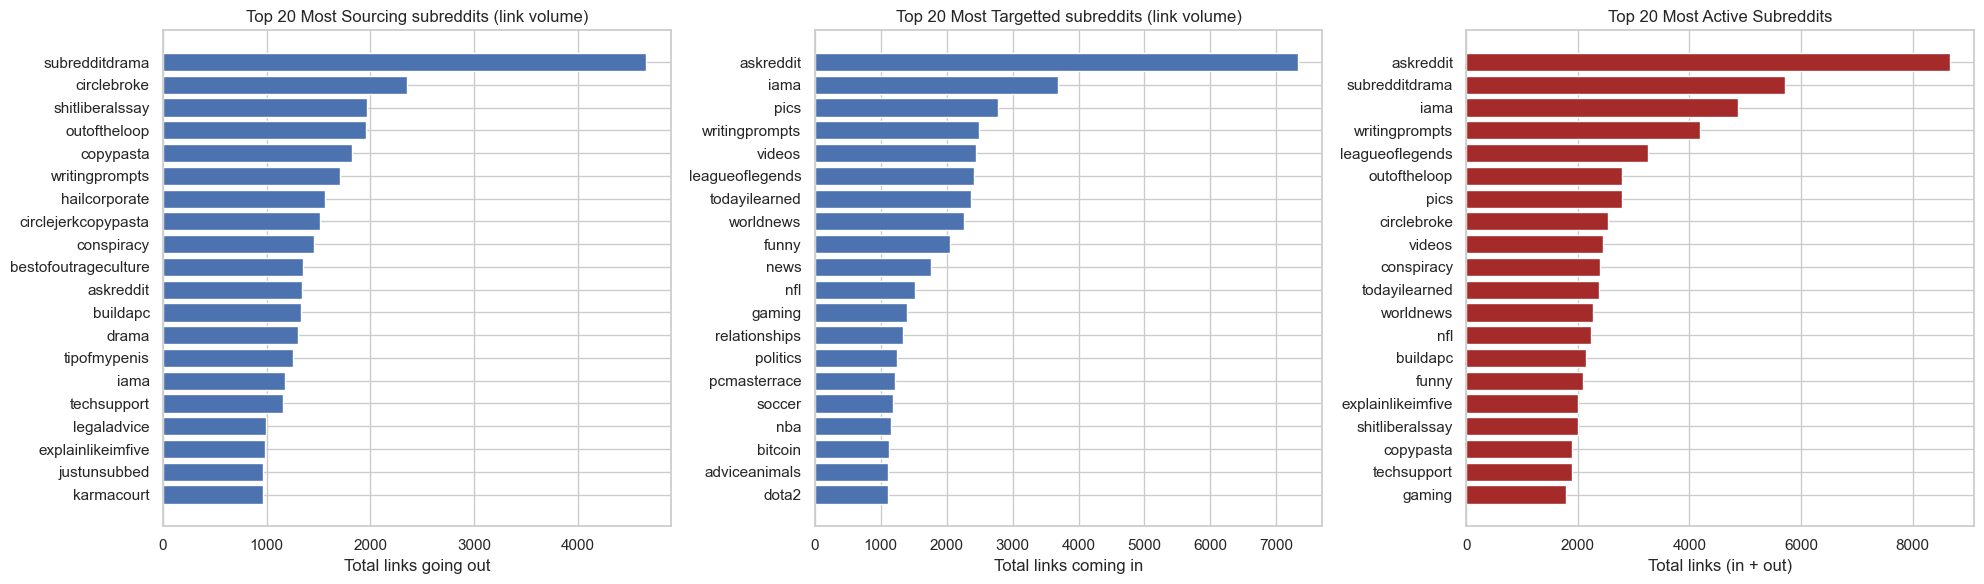

In [5]:
fig, axs = plt.subplots(1,3, figsize= (20, 6))

# Count how many times each subreddit links to others (out)
source_counts = df_body["SOURCE_SUBREDDIT"].value_counts().reset_index()
source_counts.columns = ["subreddit", "out_links"]

top_sources = source_counts.sort_values("out_links", ascending=False).head(20)
axs[0].barh(top_sources["subreddit"], top_sources["out_links"])
axs[0].invert_yaxis()
axs[0].set_title("Top 20 Most Sourcing subreddits (link volume)")
axs[0].set_xlabel("Total links going out")

# Count how many times each subreddit is linked to (in)
target_counts = df_body["TARGET_SUBREDDIT"].value_counts().reset_index()
target_counts.columns = ["subreddit", "in_links"]

top_targets = target_counts.sort_values("in_links", ascending=False).head(20)
axs[1].barh(top_targets["subreddit"], top_targets["in_links"])
axs[1].invert_yaxis()
axs[1].set_title("Top 20 Most Targetted subreddits (link volume)")
axs[1].set_xlabel("Total links coming in")


# Total activity
activity = pd.merge(source_counts, target_counts, on="subreddit", how="outer").fillna(0)
activity["total_links"] = activity["in_links"] + activity["out_links"]

top_activity = activity.sort_values("total_links", ascending=False).head(20)
axs[2].barh(top_activity["subreddit"], top_activity["total_links"], color = 'brown')
axs[2].invert_yaxis()
axs[2].set_title("Top 20 Most Active Subreddits")
axs[2].set_xlabel("Total links (in + out)")

fig.tight_layout()
fig.show()

In [6]:
activity

,subreddit,out_links,in_links,total_links
0,01001111010100000,0.0,1.0,1.0
1,0131,0.0,1.0,1.0
2,07scape,2.0,3.0,5.0
3,0b0t,0.0,1.0,1.0
4,0bservat0ry,0.0,2.0,2.0
...,...,...,...,...
35771,zxspectrum,1.0,2.0,3.0
35772,zylooxwrites,4.0,0.0,4.0
35773,zyramains,18.0,6.0,24.0
35774,zyzz,1.0,0.0,1.0


#### Network graph

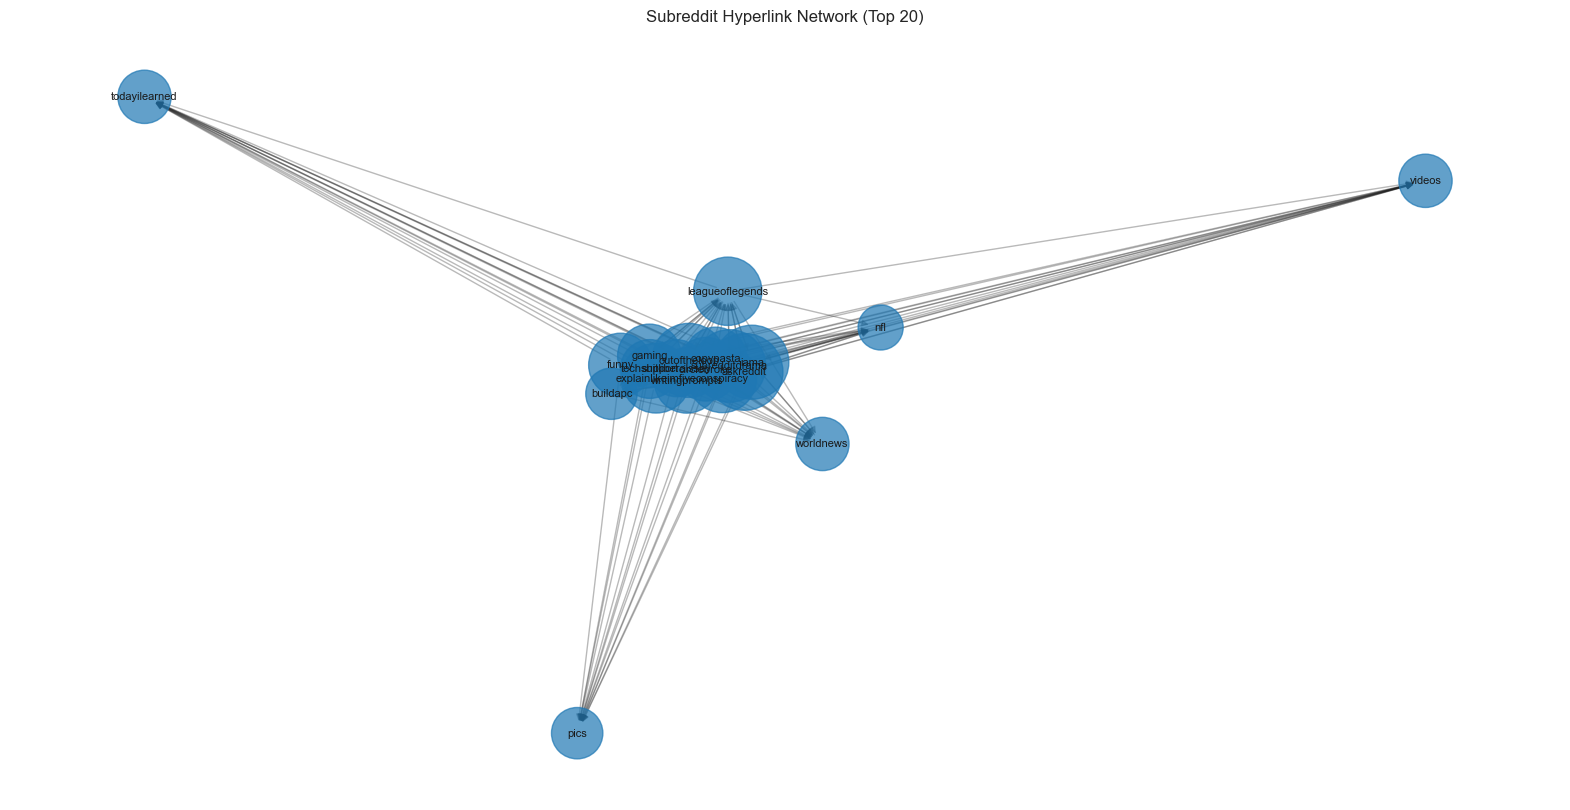

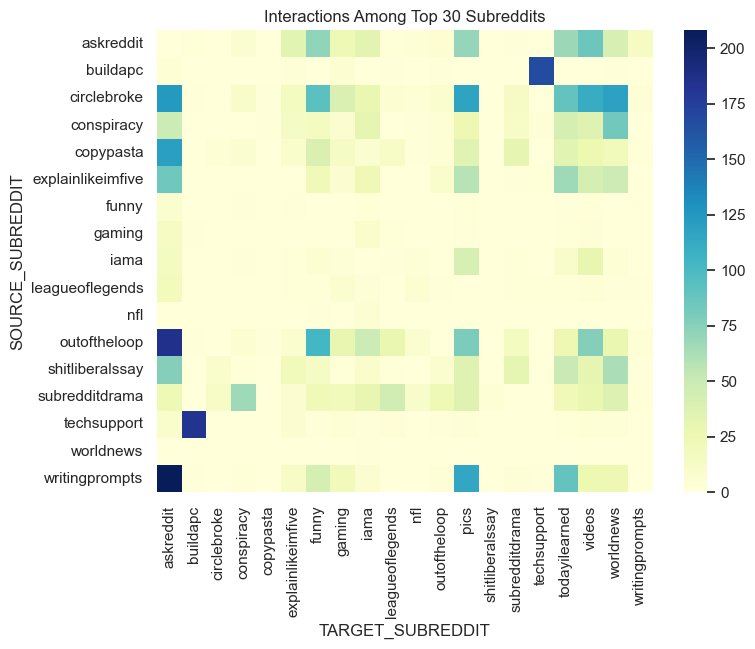

In [7]:
import networkx as nx

# Take top N subreddits by total activity
top_n = 20
top_subs = set(activity.sort_values("total_links", ascending=False).head(top_n)["subreddit"])

# Filter links that involve only those
df_top = df_body[
    df_body["SOURCE_SUBREDDIT"].isin(top_subs) &
    df_body["TARGET_SUBREDDIT"].isin(top_subs)
]

G = nx.from_pandas_edgelist(df_top, source="SOURCE_SUBREDDIT", target="TARGET_SUBREDDIT", create_using=nx.DiGraph())

deg_centrality = nx.degree_centrality(G)

plt.figure(figsize=(20, 10))
pos = nx.spring_layout(G, k=0.3)
nx.draw_networkx_nodes(G, pos, node_size=[v * 2000 for v in deg_centrality.values()], alpha=0.7)
nx.draw_networkx_edges(G, pos, alpha=0.3, arrows=True)
nx.draw_networkx_labels(G, pos, font_size=8)
plt.title(f"Subreddit Hyperlink Network (Top {top_n})")
plt.axis("off")
plt.show()


pivot = df_top.pivot_table(index="SOURCE_SUBREDDIT", columns="TARGET_SUBREDDIT", aggfunc="size", fill_value=0)
plt.figure(figsize=(8,6))
sns.heatmap(pivot, cmap="YlGnBu")
plt.title("Interactions Among Top 30 Subreddits")
plt.show()


#### Nb links over time

In [8]:
# Parse timestamp
df_body["TIMESTAMP"] = pd.to_datetime(df_body["TIMESTAMP"])
df_body["year_month"] = df_body["TIMESTAMP"].dt.to_period("M").dt.to_timestamp()

# Count interactions per month and sentiment
links_over_time_sent = (
    df_body.groupby(["year_month", "LINK_SENTIMENT"])
    .size()
    .reset_index(name="n_links")
)

links_over_time_pivot = links_over_time_sent.pivot(
    index="year_month", columns="LINK_SENTIMENT", values="n_links"
).fillna(0)

links_over_time_pivot["total"] = links_over_time_pivot.sum(axis=1)
links_over_time_pivot

LINK_SENTIMENT,-1,1,total
year_month,,,
2013-12-01,1,6,7
2014-01-01,331,4109,4440
2014-02-01,330,4101,4431
2014-03-01,462,4921,5383
2014-04-01,387,4603,4990
...,...,...,...
2016-12-01,578,7652,8230
2017-01-01,656,8138,8794
2017-02-01,534,8481,9015


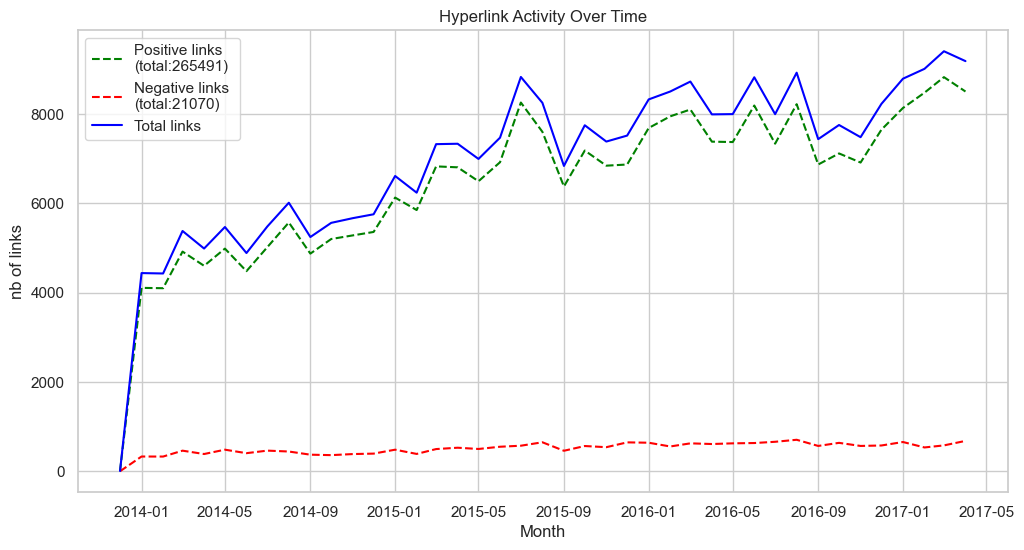

In [9]:
sentiment_counts = df_body["LINK_SENTIMENT"].value_counts()

plt.figure(figsize=(12, 6))
plt.plot(links_over_time_pivot.index, links_over_time_pivot[1], label=f"Positive links \n(total:{sentiment_counts[1]})", color="green", linestyle="--")
plt.plot(links_over_time_pivot.index, links_over_time_pivot[-1], label=f"Negative links \n(total:{sentiment_counts[-1]})", color="red", linestyle="--")
plt.plot(links_over_time_pivot.index, links_over_time_pivot["total"], label="Total links", color="blue")




plt.title("Hyperlink Activity Over Time")
plt.xlabel("Month")
plt.ylabel("nb of links")
plt.legend()
plt.grid(True)
plt.show()

#### Average sentiment per source

In [10]:
# Compute average sentiment per source subreddit
sentiment_by_sub = (
    df_body.groupby("SOURCE_SUBREDDIT")["LINK_SENTIMENT"]
    .mean()
    .reset_index()
    .rename(columns={"SOURCE_SUBREDDIT": "subreddit"})
)

top100_subs = set(
    activity.sort_values("total_links", ascending=False)
    .head(100)["subreddit"]
)

sentiment_by_sub["is_top100"] = sentiment_by_sub["subreddit"].isin(top100_subs)

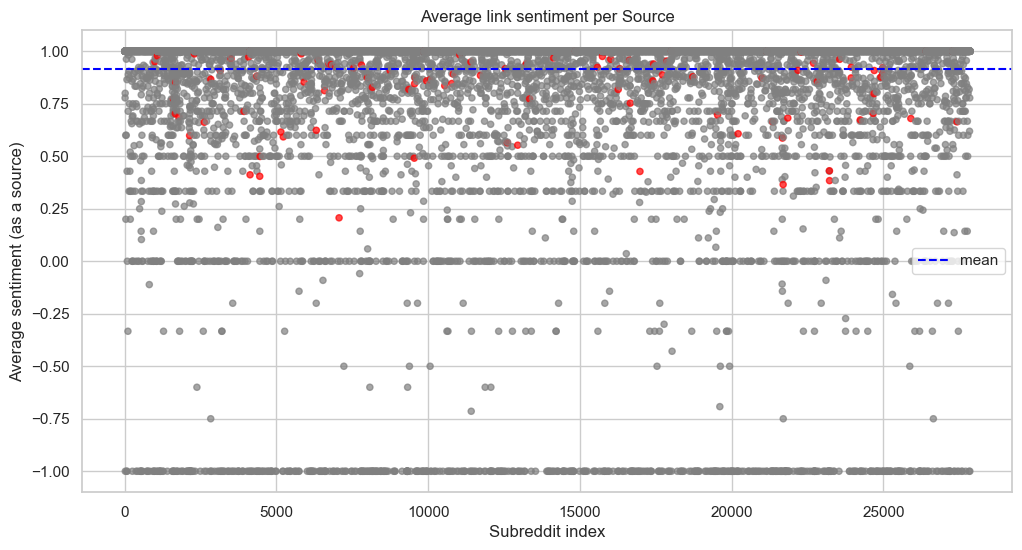

In [11]:
plt.figure(figsize=(12, 6))
plt.scatter(
    sentiment_by_sub.index,
    sentiment_by_sub["LINK_SENTIMENT"],
    c=sentiment_by_sub["is_top100"].map({True: "red", False: "gray"}),
    s=20,
    alpha=0.7
)

plt.axhline(sentiment_by_sub["LINK_SENTIMENT"].mean(), color="blue", linestyle="--", label="mean")
plt.title("Average link sentiment per Source")
plt.xlabel("Subreddit index")
plt.ylabel("Average sentiment (as a source)")
plt.legend()
plt.grid(True)
plt.show()

#### Average property score for positive VS negative links

In [ ]:
properties_expanded = df_body["PROPERTIES"].str.split(",", expand=True).astype(float)

n_cols = properties_expanded.shape[1]
properties_expanded.columns = [f"P{i+1}" for i in range(n_cols)]

properties_expanded

df_props = pd.concat([df_body["LINK_SENTIMENT"], properties_expanded], axis=1)

avg_by_sentiment = df_props.groupby("LINK_SENTIMENT").mean(numeric_only=True).T
avg_by_sentiment.columns = ["negative", "positive"]

avg_by_sentiment = avg_by_sentiment.reset_index().rename(columns={"index": "property"})

In [13]:
avg_by_sentiment

,property,negative,positive
0,P1,2165.743664,2053.787650
1,P2,1880.366398,1790.059576
2,P3,0.763307,0.750157
3,P4,0.017501,0.021110
4,P5,0.036409,0.041956
...,...,...,...
81,P82,0.001879,0.001119
82,P83,0.001531,0.001213
83,P84,0.002128,0.001647
84,P85,0.000779,0.000858


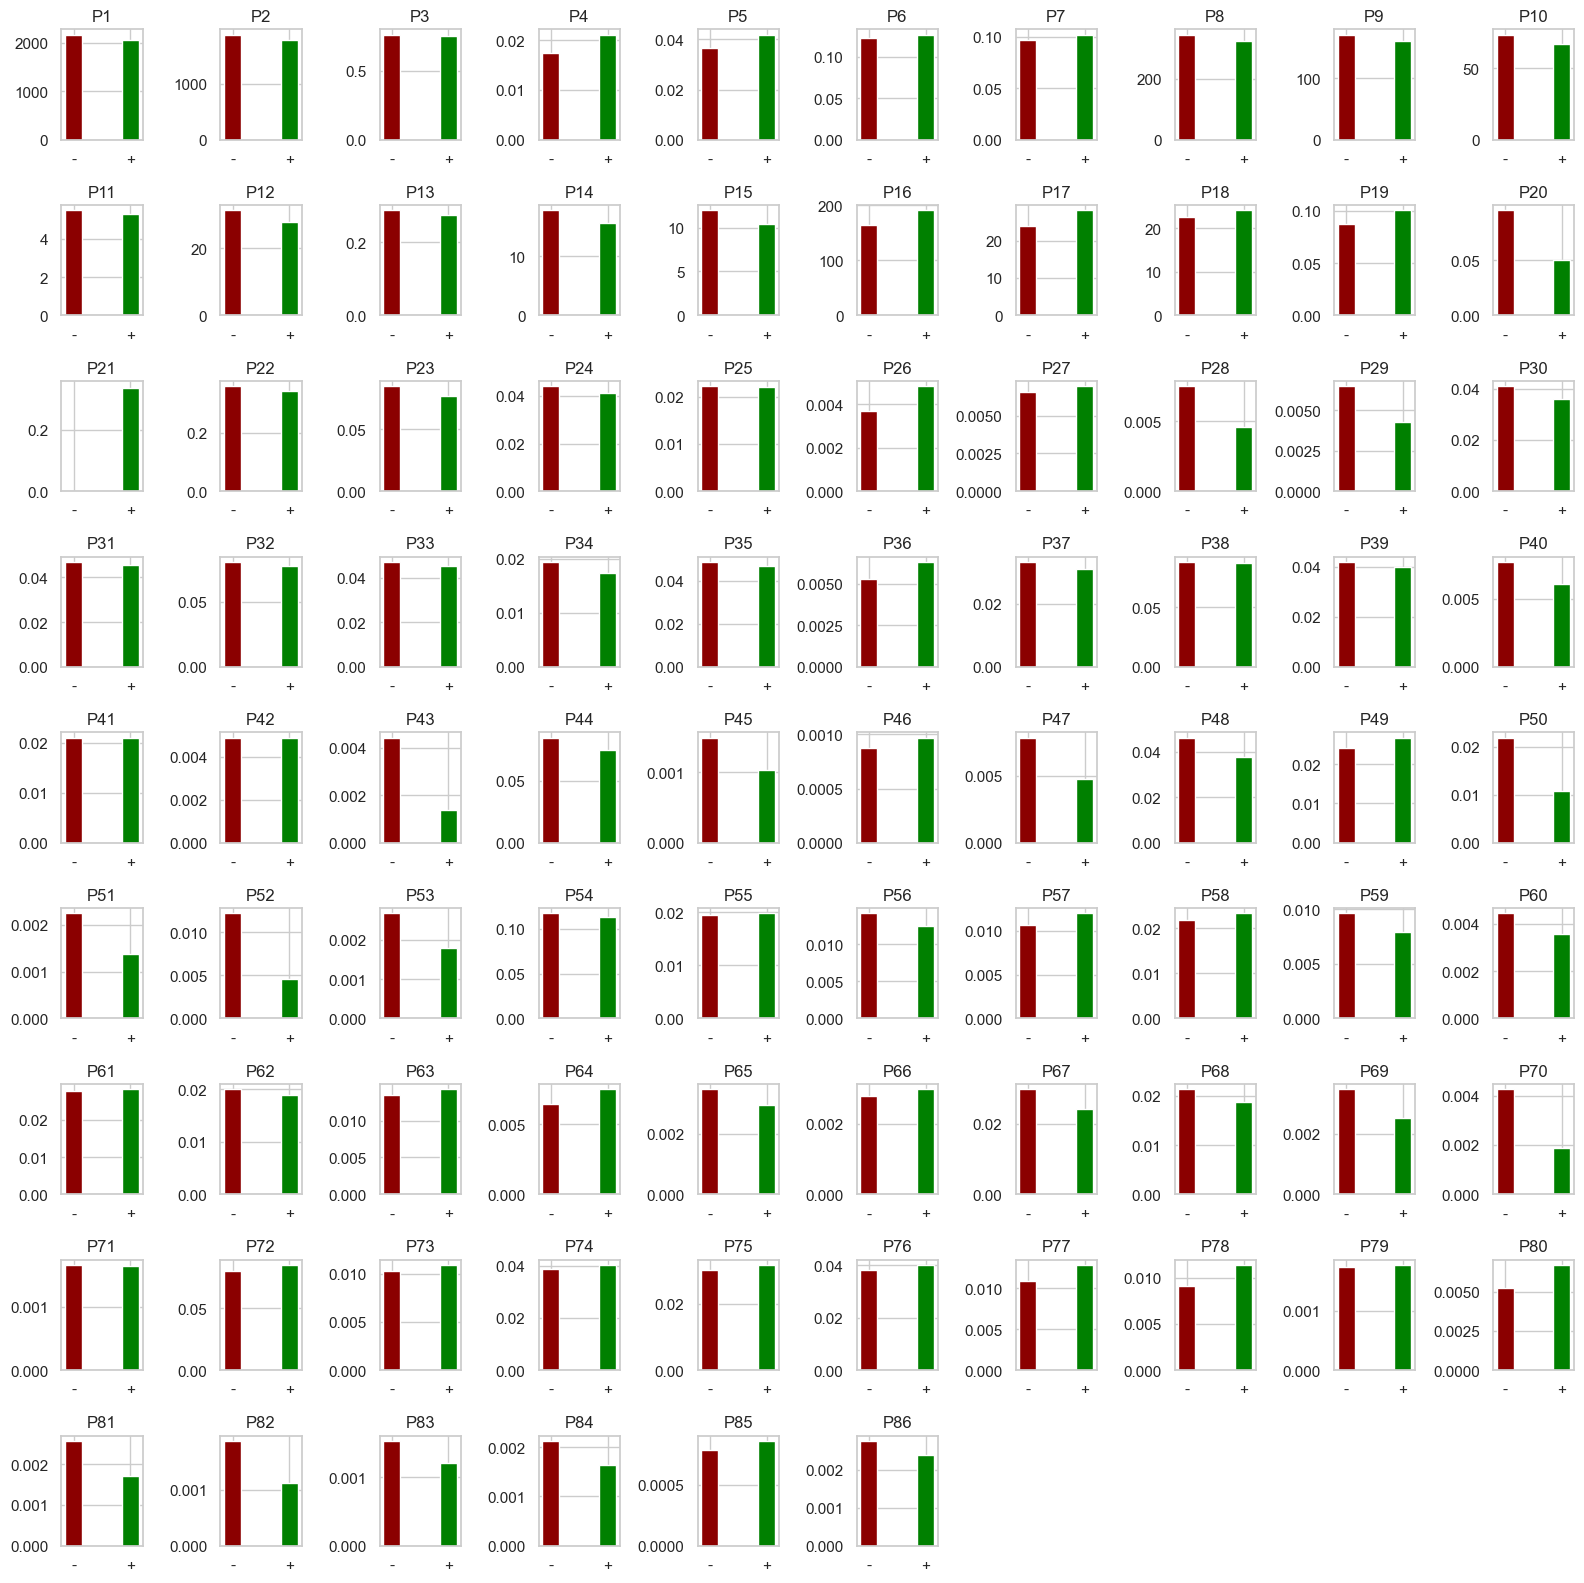

In [ ]:
fig, axes = plt.subplots(9, 10, figsize=(16, 16))  # 22x4 = 88 slots (a few empty)
axes = axes.flatten()

for i, row in avg_by_sentiment.iterrows():
    ax = axes[i]
    ax.bar(["-", "+"], [row["negative"], row["positive"]],
           color=["darkred", "green"], width=0.3)
    ax.set_title(row["property"])
    ax.set_xlabel("")
    ax.set_ylim(bottom=0)  # Make sure it starts at 0

for j in range(len(avg_by_sentiment), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()